# Лабораторная работа №4: Оценки, полученные методом максимального правдоподобия

1. ММП для равномерного распределения $U[a, b]$: оценки $a^*$, $b^*$.
2. ММП для распределения Лапласа с плотностью $\varphi(x; c, \lambda) = \frac{\lambda}{2} e^{-\lambda|x-c|}$: оценки $c^*$, $\lambda^*$.
3. Программная реализация оценок и график зависимости СКО от размера выборки (как в лаб. 3).

## Метод максимального правдоподобия

Пусть $X_1, \dots, X_n$ — н.о.р. с плотностью $f(x; \theta)$. Функция правдоподобия
$$
L(\theta) = \prod_{i=1}^n f(X_i; \theta), \qquad
\ell(\theta) = \ln L(\theta) = \sum_{i=1}^n \ln f(X_i; \theta).
$$
Оценка максимального правдоподобия (ОМП):
$$
\hat\theta_{\mathrm{MLE}} = \arg\max_\theta L(\theta) = \arg\max_\theta \ell(\theta).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
N_MC = 10**3
N_MAX = 10**4
N_TRAJ = np.unique(np.logspace(1, 4, 60).astype(int))
N_MC_SIZES = [10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000]

plt.rcParams['figure.dpi'] = 110

/home/vasil1y/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


---
# Часть I. Равномерное распределение $U[a, b]$

Плотность
$$
\varphi(x; a, b) =
\begin{cases}
\dfrac{1}{b-a}, & x \in [a, b], \\
0, & x \notin [a, b].
\end{cases}
$$

## 1. Вывод оценок ММП

Функция правдоподобия
$$
L(a, b) =
\begin{cases}
(b-a)^{-n}, & a \le X_{(1)},\; b \ge X_{(n)}, \\
0, & \text{иначе},
\end{cases}
$$
где $X_{(1)} = \min_i X_i$, $X_{(n)} = \max_i X_i$.

На допустимом множестве $\{(a,b): a \le X_{(1)},\, b \ge X_{(n)}\}$ величина $L = (b-a)^{-n}$ убывает по длине интервала $b-a$.
Минимум $b-a$ при указанных ограничениях достигается при
$$
\boxed{a^* = X_{(1)} = \min_{1\le i\le n} X_i, \qquad
b^* = X_{(n)} = \max_{1\le i\le n} X_i.}
$$

**Замечание.** ОМП смещены: $\mathbb{E}a^* = a + \dfrac{b-a}{n+1}$, $\mathbb{E}b^* = b - \dfrac{b-a}{n+1}$.
Несмещённые поправки: $\tilde a = \dfrac{n X_{(1)} - X_{(n)}}{n-1}$, $\tilde b = \dfrac{n X_{(n)} - X_{(1)}}{n-1}$, но в задании требуются именно ОМП $a^*$, $b^*$.

**Скорость сходимости.** В отличие от регулярных моделей, здесь
$$
n\,\frac{a^* - a}{b-a} \xrightarrow{d} \mathrm{Exp}(1), \qquad
n\,\frac{b - b^*}{b-a} \xrightarrow{d} \mathrm{Exp}(1),
$$
то есть СКО убывает как $O(1/n)$, а не $O(1/\sqrt n)$. Точные формулы:
$$
\mathbb{D}a^* = \mathbb{D}b^* = \frac{n(b-a)^2}{(n+1)^2(n+2)}.
$$

In [2]:
def mle_uniform(x):
    """ОМП для U[a,b]: a* = min, b* = max. x — shape (..., n)."""
    return np.stack([x.min(axis=-1), x.max(axis=-1)], axis=-1)


UNIF_TRUE = np.array([0.0, 1.0])
UNIF_PARAMS = ['a', 'b']

# проверка на одной выборке
rng = np.random.default_rng(SEED)
x_demo = rng.uniform(0, 1, 20)
a_hat, b_hat = mle_uniform(x_demo)
print(f'выборка (n=20): min={x_demo.min():.4f}, max={x_demo.max():.4f}')
print(f'a* = {a_hat:.4f},  b* = {b_hat:.4f}')

выборка (n=20): min=0.0638, max=0.9756
a* = 0.0638,  b* = 0.9756


### Траектория оценок при росте $n$

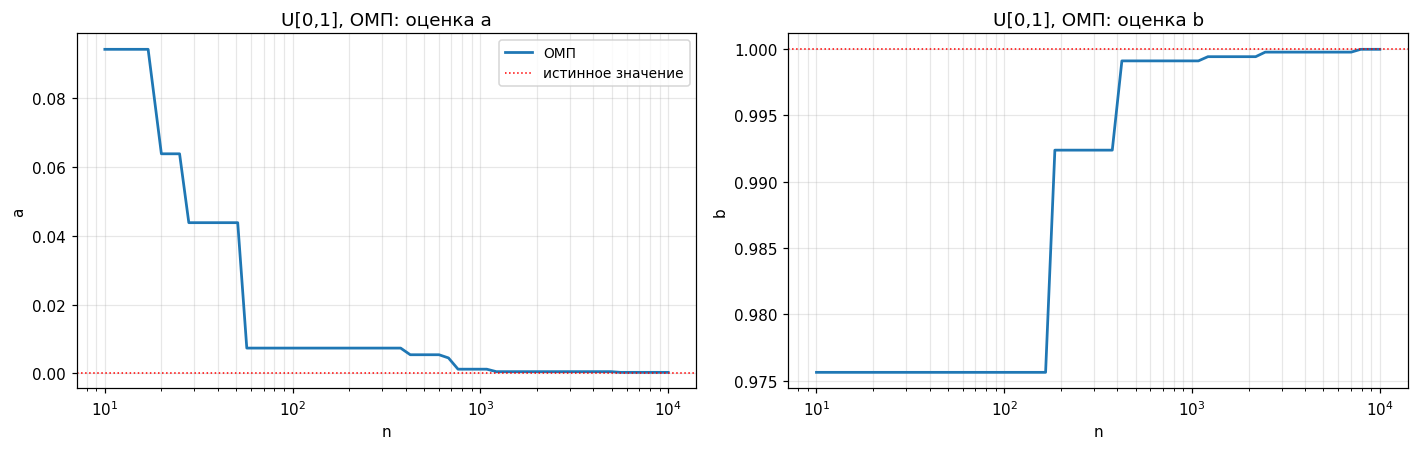

In [3]:
def prefix_mle_uniform(x, sizes):
    """ОМП по префиксам одной выборки для каждого n из sizes."""
    sizes = np.asarray(sizes)
    # running min / max
    rmin = np.minimum.accumulate(x)
    rmax = np.maximum.accumulate(x)
    return np.stack([rmin[sizes - 1], rmax[sizes - 1]], axis=1)


def plot_trajectories(sizes, estimates, param_names, true_vals, title, labels=None):
    """estimates: dict name -> array (len(sizes), p) или один массив (len(sizes), p)."""
    if isinstance(estimates, np.ndarray):
        estimates = {'ОМП': estimates}
    if labels is None:
        labels = list(estimates)
    p = len(param_names)
    fig, axes = plt.subplots(1, p, figsize=(6.5 * p, 4.2), squeeze=False)
    colors = ['tab:blue', 'tab:orange', 'tab:green', 'black']
    for i in range(p):
        ax = axes[0, i]
        for j, name in enumerate(labels):
            ax.plot(sizes, estimates[name][:, i], label=name, color=colors[j % len(colors)], lw=1.8)
        ax.axhline(true_vals[i], color='red', lw=1, ls=':', label='истинное значение')
        ax.set_xscale('log')
        ax.set_xlabel('n')
        ax.set_ylabel(param_names[i])
        ax.set_title(f'{title}: оценка {param_names[i]}')
        ax.grid(True, which='both', alpha=0.3)
    axes[0, 0].legend(fontsize=9)
    plt.tight_layout()
    plt.show()


rng = np.random.default_rng(SEED)
x_unif = rng.uniform(0, 1, N_MAX)
traj_unif = prefix_mle_uniform(x_unif, N_TRAJ)
plot_trajectories(N_TRAJ, traj_unif, UNIF_PARAMS, UNIF_TRUE, 'U[0,1], ОМП')

## 3. СКО оценок $a^*$, $b^*$ в зависимости от $n$

Для каждого $n$ генерируем $N = 10^3$ выборок из $U[0,1]$, считаем ОМП и выборочное СКО
$$
\widehat{\sigma}(\hat\theta) = \sqrt{\frac{1}{N-1}\sum_{r=1}^{N}\bigl(\hat\theta^{(r)} - \overline{\hat\theta}\bigr)^2}.
$$
Пунктиром — точная формула $\sigma(a^*) = \sigma(b^*) = \sqrt{\dfrac{n}{(n+1)^2(n+2)}}$ (при $b-a = 1$).

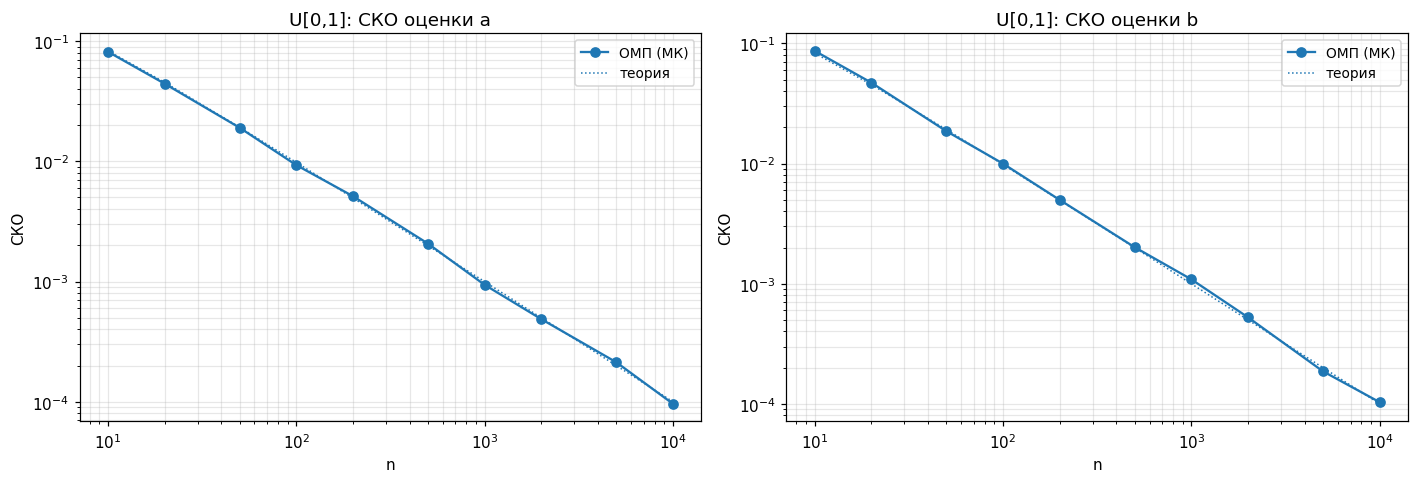


СКО оценки a (в скобках — смещение)
       n            10            20            50           100           200           500          1000          2000          5000         10000
     ОМП 0.0816 (+0.0892) 0.0443 (+0.0475) 0.0191 (+0.0196) 0.0093 (+0.0096) 0.0051 (+0.0052) 0.0021 (+0.0021) 0.0009 (+0.0010) 0.0005 (+0.0005) 0.0002 (+0.0002) 0.0001 (+0.0001)

СКО оценки b (в скобках — смещение)
       n            10            20            50           100           200           500          1000          2000          5000         10000
     ОМП 0.0867 (-0.0928) 0.0471 (-0.0492) 0.0186 (-0.0194) 0.0100 (-0.0100) 0.0050 (-0.0049) 0.0020 (-0.0022) 0.0011 (-0.0010) 0.0005 (-0.0005) 0.0002 (-0.0002) 0.0001 (-0.0001)


In [4]:
def monte_carlo_mle(estimator, sampler, sizes, n_mc, seed, true_vals):
    """Возвращает {n: (mean, std)} по n_mc выборкам."""
    rng = np.random.default_rng(seed)
    out = {}
    for n in sizes:
        x = sampler(rng, (n_mc, n))
        est = estimator(x)
        out[n] = (est.mean(axis=0), est.std(axis=0, ddof=1))
    return out


def plot_std(mc, sizes, param_names, true_sd_fn, title, method_name='ОМП'):
    """true_sd_fn(n) -> array shape (p,) теоретических СКО."""
    p = len(param_names)
    fig, axes = plt.subplots(1, p, figsize=(6.5 * p, 4.5), squeeze=False)
    ns = np.asarray(sizes, float)
    for i in range(p):
        ax = axes[0, i]
        sd_emp = np.array([mc[n][1][i] for n in sizes])
        ax.plot(ns, sd_emp, 'o-', color='tab:blue', label=f'{method_name} (МК)', ms=6)
        if true_sd_fn is not None:
            sd_th = np.array([true_sd_fn(n)[i] for n in sizes])
            ax.plot(ns, sd_th, color='tab:blue', lw=1, ls=':', label='теория')
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlabel('n')
        ax.set_ylabel('СКО')
        ax.set_title(f'{title}: СКО оценки {param_names[i]}')
        ax.grid(True, which='both', alpha=0.3)
        ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()


def print_mc_table(mc, sizes, param_names, true_vals):
    for i, pn in enumerate(param_names):
        print(f'\nСКО оценки {pn} (в скобках — смещение)')
        print(f'{"n":>8}' + ''.join(f'{n:>14d}' for n in sizes))
        row = ''.join(f'{mc[n][1][i]:>7.4f} ({mc[n][0][i] - true_vals[i]:+.4f})'
                      for n in sizes)
        print(f'{"ОМП":>8}{row}')


def unif_true_sd(n, length=1.0):
    # D(a*) = D(b*) = n * L^2 / ((n+1)^2 (n+2))
    return np.full(2, np.sqrt(n * length**2 / ((n + 1)**2 * (n + 2))))


mc_unif = monte_carlo_mle(
    mle_uniform,
    lambda rng, size: rng.uniform(0, 1, size),
    N_MC_SIZES, N_MC, SEED + 1, UNIF_TRUE,
)

plot_std(mc_unif, N_MC_SIZES, UNIF_PARAMS, unif_true_sd, 'U[0,1]')
print_mc_table(mc_unif, N_MC_SIZES, UNIF_PARAMS, UNIF_TRUE)

### Выводы по равномерному распределению

1. **ОМП:** $a^* = X_{(1)}$, $b^* = X_{(n)}$.
2. **Состоятельность:** при $n \to \infty$ оценки сходятся к $(a, b)$; на графике траекторий видно быстрое приближение к $(0, 1)$.
3. **СКО** убывает как $O(1/n)$ (наклон $-1$ на log-log), что быстрее обычной регулярной скорости $1/\sqrt n$. Эмпирические СКО совпадают с точной формулой уже при малых $n$.
4. Смещение положительно для $a^*$ и отрицательно для $b^*$ (оценки «сжимают» интервал) и убывает как $O(1/n)$.

---
# Часть II. Распределение Лапласа

Плотность
$$
\varphi(x; c, \lambda) = \frac{\lambda}{2}\, e^{-\lambda |x - c|}, \qquad \lambda > 0.
$$
Генеральное распределение в эксперименте: $c = 0$, $\lambda = 1$.

## 2. Вывод оценок ММП

Правдоподобие
$$
L(c, \lambda) = \Bigl(\frac{\lambda}{2}\Bigr)^n \exp\Bigl(-\lambda \sum_{i=1}^n |X_i - c|\Bigr).
$$
Логарифм правдоподобия
$$
\ell(c, \lambda) = n\ln\lambda - n\ln 2 - \lambda \sum_{i=1}^n |X_i - c|.
$$

### Оценка параметра $c$

При фиксированном $\lambda$ максимум $\ell$ по $c$ эквивалентен минимуму суммы абсолютных отклонений:
$$
c^* = \arg\min_c \sum_{i=1}^n |X_i - c|.
$$
Известно, что минимум достигается в **выборочной медиане**:
$$
\boxed{c^* = \mathrm{med}(X_1, \dots, X_n).}
$$
При нечётном $n = 2m+1$: $c^* = X_{(m+1)}$;
при чётном $n = 2m$ любой $c \in [X_{(m)}, X_{(m+1)}]$ — ОМП; берём среднее $\tfrac12\bigl(X_{(m)} + X_{(m+1)}\bigr)$.

### Оценка параметра $\lambda$

Подставляя $c^*$ и дифференцируя по $\lambda$:
$$
\frac{\partial\ell}{\partial\lambda} = \frac{n}{\lambda} - \sum_{i=1}^n |X_i - c^*| = 0
\quad\Rightarrow\quad
\boxed{\lambda^* = \dfrac{n}{\sum_{i=1}^n |X_i - c^*|}.}
$$
То есть $\lambda^*$ — обратное к среднему абсолютному отклонению от медианы.

### Асимптотика (регулярный случай)

Информация Фишера: $I_c = \lambda^2$, $I_\lambda = 1/\lambda^2$ (параметры асимптотически независимы). Поэтому
$$
\sqrt n\,(c^* - c) \xrightarrow{d} N\bigl(0,\, 1/\lambda^2\bigr), \qquad
\sqrt n\,(\lambda^* - \lambda) \xrightarrow{d} N\bigl(0,\, \lambda^2\bigr).
$$
СКО $\sim 1/(\lambda\sqrt n)$ для $c^*$ и $\sim \lambda/\sqrt n$ для $\lambda^*$.

In [5]:
def mle_laplace(x):
    """ОМП для Лапласа: c* = median, λ* = n / sum|x_i - c*|. x — shape (..., n)."""
    c = np.median(x, axis=-1)
    mad = np.abs(x - c[..., None]).sum(axis=-1)
    n = x.shape[-1]
    lam = n / mad
    return np.stack([c, lam], axis=-1)


LAP_TRUE = np.array([0.0, 1.0])  # c=0, λ=1
LAP_PARAMS = ['c', 'λ']

rng = np.random.default_rng(SEED)
x_demo = rng.laplace(0.0, 1.0, 20)  # scipy/numpy: scale = 1/λ
c_hat, lam_hat = mle_laplace(x_demo)
print(f'выборка (n=20): median={np.median(x_demo):.4f}, MAD_sum={np.abs(x_demo - np.median(x_demo)).sum():.4f}')
print(f'c* = {c_hat:.4f},  λ* = {lam_hat:.4f}')

выборка (n=20): median=0.3225, MAD_sum=17.6409
c* = 0.3225,  λ* = 1.1337


### Траектория оценок при росте $n$

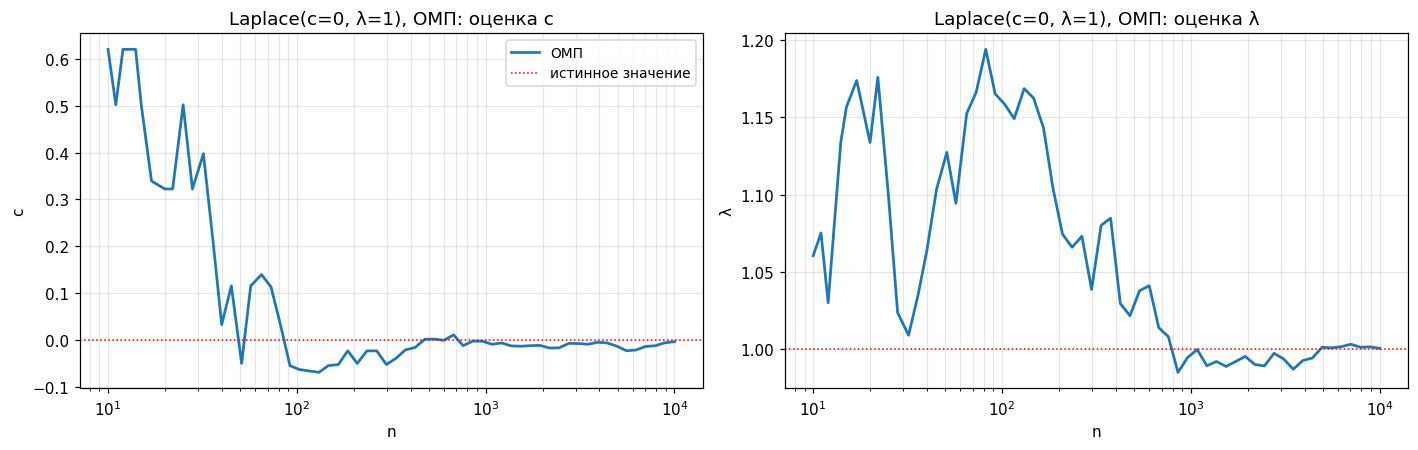

In [6]:
def prefix_mle_laplace(x, sizes):
    """ОМП Лапласа по префиксам одной выборки."""
    sizes = np.asarray(sizes)
    out = np.empty((len(sizes), 2))
    for i, n in enumerate(sizes):
        out[i] = mle_laplace(x[:n])
    return out


rng = np.random.default_rng(SEED)
# numpy.laplace(loc, scale): density (1/(2b)) exp(-|x-μ|/b), так что λ = 1/scale
x_lap = rng.laplace(0.0, 1.0, N_MAX)
traj_lap = prefix_mle_laplace(x_lap, N_TRAJ)
plot_trajectories(N_TRAJ, traj_lap, LAP_PARAMS, LAP_TRUE, 'Laplace(c=0, λ=1), ОМП')

## 3. СКО оценок $c^*$, $\lambda^*$ в зависимости от $n$

Пунктиром — асимптотика $\sigma_c \approx 1/(\lambda\sqrt n)$, $\sigma_\lambda \approx \lambda/\sqrt n$.

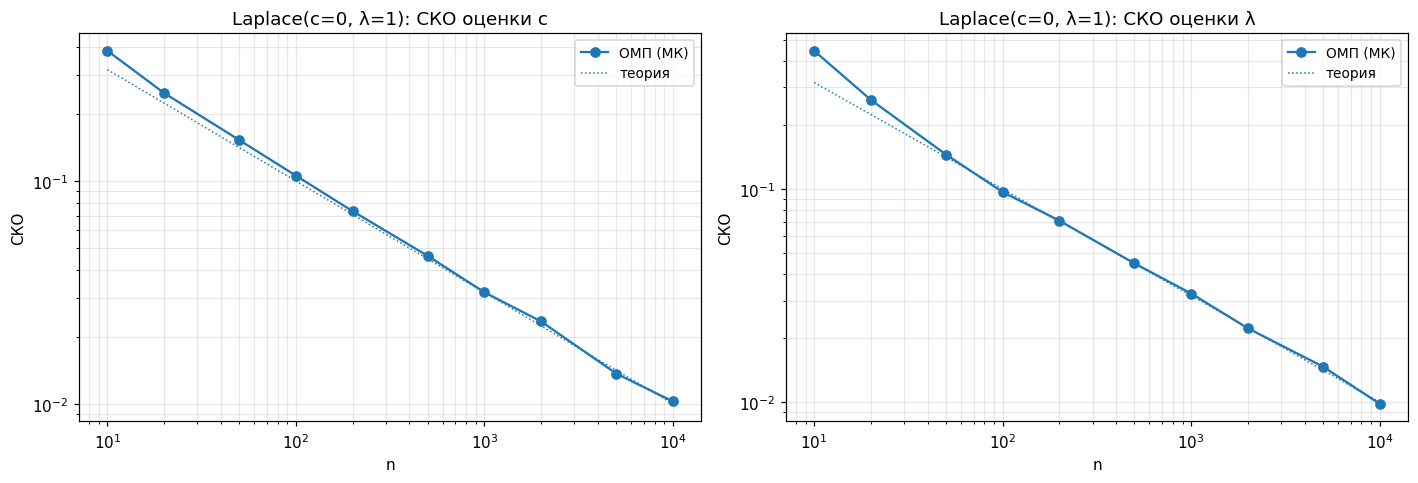


СКО оценки c (в скобках — смещение)
       n            10            20            50           100           200           500          1000          2000          5000         10000
     ОМП 0.3842 (-0.0132) 0.2481 (-0.0003) 0.1528 (+0.0021) 0.1057 (-0.0003) 0.0732 (+0.0020) 0.0462 (-0.0001) 0.0317 (-0.0004) 0.0234 (+0.0005) 0.0137 (-0.0003) 0.0102 (-0.0005)

СКО оценки λ (в скобках — смещение)
       n            10            20            50           100           200           500          1000          2000          5000         10000
     ОМП 0.4453 (+0.1823) 0.2618 (+0.0864) 0.1453 (+0.0268) 0.0968 (+0.0101) 0.0710 (+0.0093) 0.0448 (+0.0021) 0.0324 (+0.0017) 0.0222 (+0.0011) 0.0147 (+0.0003) 0.0098 (+0.0002)


In [7]:
def lap_asymp_sd(n, c=0.0, lam=1.0):
    return np.array([1.0 / (lam * np.sqrt(n)), lam / np.sqrt(n)])


mc_lap = monte_carlo_mle(
    mle_laplace,
    lambda rng, size: rng.laplace(0.0, 1.0, size),
    N_MC_SIZES, N_MC, SEED + 2, LAP_TRUE,
)

plot_std(mc_lap, N_MC_SIZES, LAP_PARAMS, lap_asymp_sd, 'Laplace(c=0, λ=1)')
print_mc_table(mc_lap, N_MC_SIZES, LAP_PARAMS, LAP_TRUE)

### Выводы по распределению Лапласа

1. **ОМП:** $c^* = \mathrm{med}(X)$, $\lambda^* = n \big/ \sum_i |X_i - c^*|$.
2. **Состоятельность:** обе оценки сходятся к $(c, \lambda) = (0, 1)$ при $n \to \infty$.
3. **СКО** убывает как $O(1/\sqrt n)$ (регулярный случай). Эмпирические СКО при больших $n$ близки к асимптотике $1/\sqrt n$ для обоих параметров (при $\lambda = 1$).
4. Оценка $c^*$ — робастная (медиана); $\lambda^*$ чувствительнее к хвостам через сумму абсолютных отклонений.

---
# Сравнение скоростей сходимости

На одном графике — СКО оценок границ равномерного ($\sim 1/n$) и параметров Лапласа ($\sim 1/\sqrt n$).

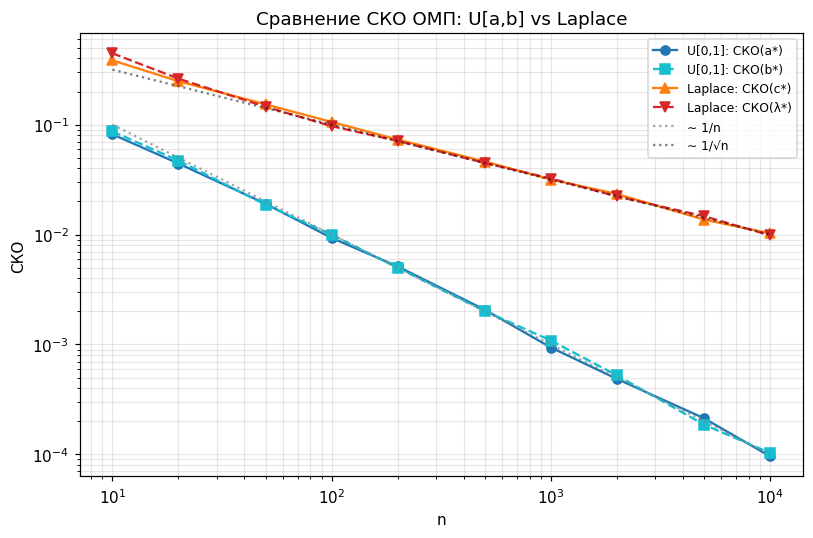

In [8]:
ns = np.asarray(N_MC_SIZES, float)

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(ns, [mc_unif[n][1][0] for n in N_MC_SIZES], 'o-', label='U[0,1]: СКО(a*)', color='tab:blue')
ax.plot(ns, [mc_unif[n][1][1] for n in N_MC_SIZES], 's--', label='U[0,1]: СКО(b*)', color='tab:cyan')
ax.plot(ns, [mc_lap[n][1][0] for n in N_MC_SIZES], '^-', label='Laplace: СКО(c*)', color='tab:orange')
ax.plot(ns, [mc_lap[n][1][1] for n in N_MC_SIZES], 'v--', label='Laplace: СКО(λ*)', color='tab:red')

# ориентиры порядков
ax.plot(ns, 1 / ns, ':', color='gray', alpha=0.7, label='∼ 1/n')
ax.plot(ns, 1 / np.sqrt(ns), ':', color='black', alpha=0.5, label='∼ 1/√n')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('n')
ax.set_ylabel('СКО')
ax.set_title('Сравнение СКО ОМП: U[a,b] vs Laplace')
ax.grid(True, which='both', alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

---
# Общие выводы

1. **Равномерное $U[a,b]$:** $a^* = X_{(1)}$, $b^* = X_{(n)}$. Модель нерегулярна (носитель зависит от параметров) → СКО $\sim 1/n$.
2. **Лаплас:** $c^* = \mathrm{median}$, $\lambda^* = n/\sum|X_i-c^*|$. Регулярная модель → СКО $\sim 1/\sqrt n$, достигается граница Рао–Крамера.
3. Эмпирические СКО по $10^3$ выборкам подтверждают теоретические порядки убывания ошибки с ростом $n$.